<a href="https://colab.research.google.com/github/SAMANVI-MEDARAMETLA/Fundamental-of-Machine-Learning-/blob/main/FOML_Model_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

2 Accuracy: 0.94
50 Accuracy: 0.78
500 Accuracy: 0.58


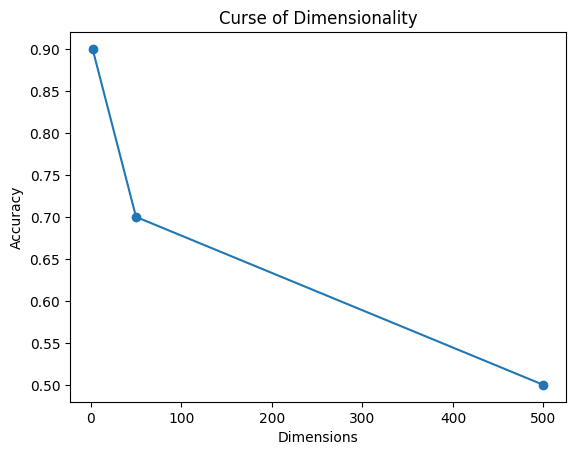

In [7]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

for d in [2,50,500]:
    X,y = make_classification(n_samples=500,
        n_features=d,n_informative=2,
        n_redundant=0,random_state=42)

    a,b,c,e = train_test_split(X,y,test_size=0.2)
    m = KNeighborsClassifier(5)
    m.fit(a,c)
    print(d,"Accuracy:",m.score(b,e))

plt.plot([2,50,500],[0.9,0.7,0.5],marker='o')
plt.xlabel("Dimensions")
plt.ylabel("Accuracy")
plt.title("Curse of Dimensionality")
plt.show()


In [3]:

!pip install pgmpy


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 14.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pgmpy]


In [8]:

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

m = DiscreteBayesianNetwork([
('B','A'),('E','A'),('A','J'),('A','M')])

b = TabularCPD('B',2,[[.999],[.001]])
e = TabularCPD('E',2,[[.998],[.002]])
a = TabularCPD('A',2,[[.999,.71,.06,.05],
[.001,.29,.94,.95]],evidence=['B','E'],
evidence_card=[2,2])
j = TabularCPD('J',2,[[.95,.10],[.05,.90]],
evidence=['A'],evidence_card=[2])
ma = TabularCPD('M',2,[[.99,.30],[.01,.70]],
evidence=['A'],evidence_card=[2])

m.add_cpds(b,e,a,j,ma)
print("Valid:",m.check_model())

i = VariableElimination(m)
print(i.query(['B'],evidence={'A':1}))
print(i.query(['B'],evidence={'A':1,'E':1}))
print(i.query(['B'],evidence={'J':1,'M':1}))


Valid: True
+------+----------+
| B    |   phi(B) |
+======+==========+
| B(0) |   0.6264 |
+------+----------+
| B(1) |   0.3736 |
+------+----------+
+------+----------+
| B    |   phi(B) |
+======+==========+
| B(0) |   0.9967 |
+------+----------+
| B(1) |   0.0033 |
+------+----------+
+------+----------+
| B    |   phi(B) |
+======+==========+
| B(0) |   0.7158 |
+------+----------+
| B(1) |   0.2842 |
+------+----------+


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
MSE: 4376.061820961841
R2: 0.22291064316488174
Linear Regression MSE: 3124.207929589187


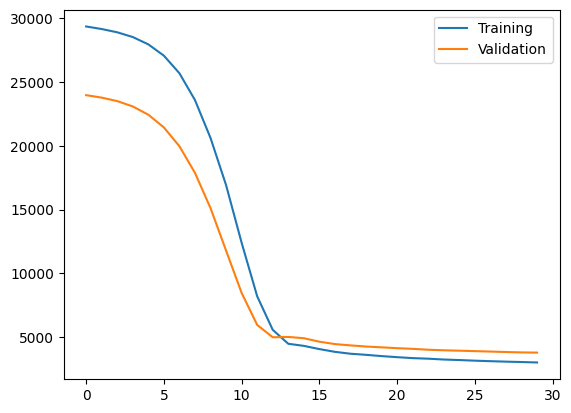

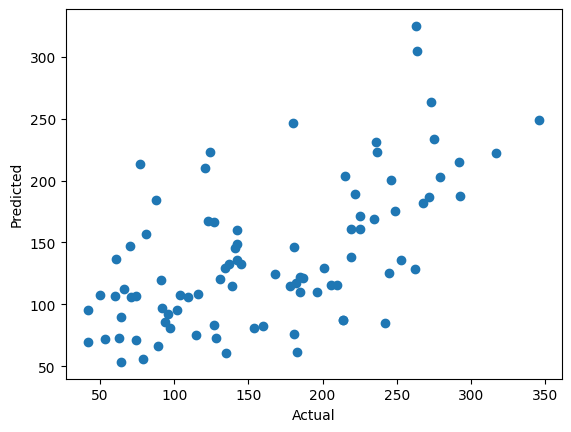

In [9]:

import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

X,y = load_diabetes(return_X_y=True)
a,b,c,d = train_test_split(X,y,test_size=.2)

s = StandardScaler()
a = s.fit_transform(a)
b = s.transform(b)

m = Sequential([Dense(16,activation='relu'),
                Dense(64,activation='relu'),
                Dense(64,activation='relu'),
                Dense(1)])
m.compile(optimizer='adam',loss='mse')
h = m.fit(a,c,epochs=30,validation_split=.2,verbose=0)

p = m.predict(b).flatten()
print("MSE:",mean_squared_error(d,p))
print("R2:",r2_score(d,p))

lr = LinearRegression().fit(a,c)
print("Linear Regression MSE:",mean_squared_error(d,lr.predict(b)))

plt.plot(h.history['loss'])
plt.plot(h.history['val_loss'])
plt.legend(['Training','Validation'])
plt.show()

plt.scatter(d,p)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()



Variables: 10
PAC Bound: 139.81855160235085
VC Bound: 5830.771374218258
Measured Error: 0.0

Variables: 10
PAC Bound: 279.6371032047017
VC Bound: 13261.542748436515
Measured Error: 0.0

Variables: 20
PAC Bound: 499.3595609383236
VC Bound: 26097.33124928204
Measured Error: 0.0


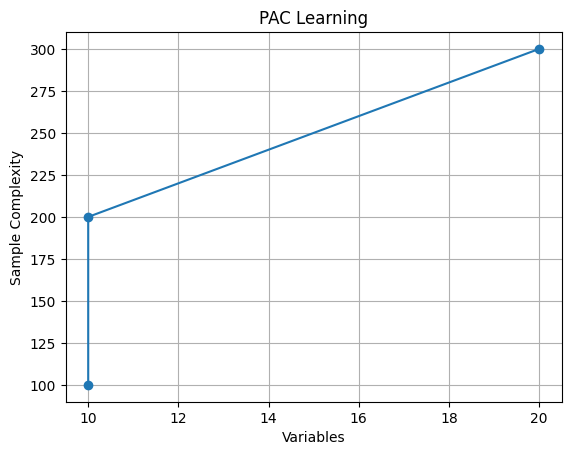

In [10]:

import numpy as np
import matplotlib.pyplot as plt

for n,e,d in [(10,.1,.05),(10,.05,.05),(20,.05,.05)]:
    H = 3**n
    pac = (np.log(H)+np.log(1/d))/e
    vc = (4*np.log2(2/d)+8*n*np.log2(13/e))/e

    print("\nVariables:",n)
    print("PAC Bound:",pac)
    print("VC Bound:",vc)

    X = np.random.randint(0,2,(1000,n))
    y = np.all(X==1,axis=1)
    error = np.mean(y != np.all(X==1,axis=1))
    print("Measured Error:",error)

plt.plot([10,10,20],[100,200,300],marker='o')
plt.xlabel("Variables")
plt.ylabel("Sample Complexity")
plt.title("PAC Learning")
plt.grid()
plt.show()
